# Exploring the California Housing dataset

This notebook is a first look at the California Housing data, before any modelling. This stage is called **exploratory data analysis (EDA)**: getting to know what the data contains, how it is distributed, and whether anything needs cleaning.

The question behind it: **what makes a neighbourhood's houses expensive?** The aim of the project is to predict house prices, and what we learn here shows which columns a model is likely to find useful.

The notebook has three parts:

- **Sections 1 to 5** get to know the data: load it, summarise it, check for gaps, and look at the prices.
- **Sections 6 to 9** each ask one question about what is linked to price.
- **Section 10** sums up the findings.

Run the cells in order from the top, because later cells use variables created by earlier ones.

## 1. Load the data

The first three lines are **imports**: they load the libraries this notebook uses. pandas handles tables, matplotlib draws plots, and scikit-learn supplies the dataset. Keeping every import in the first code cell shows a reader at a glance what the notebook needs.

`fetch_california_housing` downloads the dataset the first time it runs and reuses the saved copy after that. Passing `as_frame=True` returns it as a pandas **DataFrame**, a table with named columns.

`data.frame` holds the full table: 8 feature columns plus the target, `MedHouseVal` (median house value, in units of $100,000). Each row is one census block group, a small neighbourhood.

`df.head()` shows the first 5 rows, a quick check that the data loaded as expected.

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Summarise the numbers

`df.describe()` calculates summary statistics for every numeric column:

- `count`: how many values the column has.
- `mean`: the average.
- `std`: the standard deviation, a measure of how spread out the values are.
- `min` and `max`: the smallest and largest values.
- `25%`, `50%`, `75%`: the values below which a quarter, half and three quarters of the rows fall. The `50%` row is the **median**.

This is a quick way to spot odd values. Here, the `max` of `MedHouseVal` is 5.00001 and the `max` of `HouseAge` is 52: both columns were capped when the data was collected.

In [26]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 3. Show every column and read the documentation

The tables above hide the middle columns behind `...` because pandas shortens wide tables by default. `pd.set_option("display.max_columns", None)` removes that limit, so `df.head()` now shows all 9 columns.

`data.DESCR` is the description that ships with the dataset. It explains what each column means, where the data came from, and the units of the target.

In [27]:
pd.set_option("display.max_columns", None)
print(data.DESCR)
df.head()

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 4. Check for missing values

Real datasets often have gaps: cells where no value was recorded. pandas shows these as `NaN` ("not a number"). Most machine learning models cannot handle `NaN`, so we check for gaps before going any further.

`df.isna()` returns a table of the same shape, with `True` wherever a value is missing. `.sum()` then adds up each column, counting `True` as 1 and `False` as 0. The result is the number of missing values per column.

The documentation above says "Missing Attribute Values: None". This cell confirms it: a column of zeros means the dataset is complete and needs no cleaning for missing data.

In [28]:
# isna() marks each missing cell as True; sum() counts the Trues per column
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## 5. Plot a histogram of house prices

A **histogram** shows how values are spread out. It splits the range of prices into equal-width intervals called **bins**, then draws one bar per bin. The taller the bar, the more block groups have a price in that interval.

We plot `MedHouseVal` because it is the **target**: the value a model will later try to predict. Knowing its shape first helps us choose and judge a model.

Things to look for in the plot:

- **Where the peak is**: the most common price range.
- **A long tail to the right**: a few expensive areas stretch the plot out. This is called a *right-skewed* distribution.
- **A tall spike at the far right (5.0)**: values above $500,000 were all recorded as $500,001, so they pile up in the last bar. This is the cap we saw in the `max` row of `describe()`.

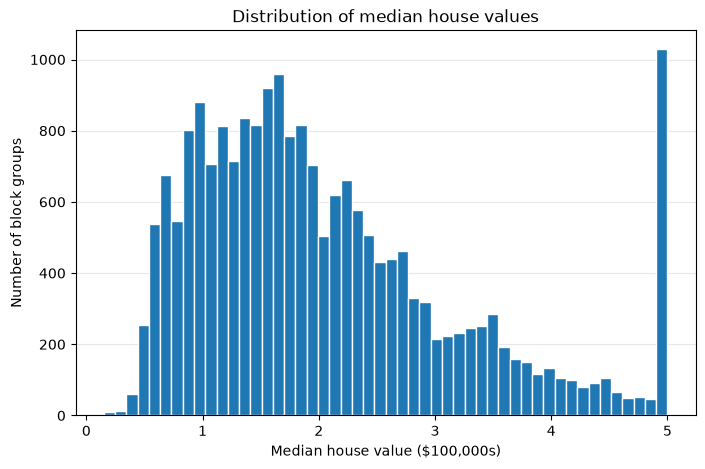

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))

# bins=50 splits the price range into 50 equal-width bars
ax.hist(df["MedHouseVal"], bins=50, edgecolor="white")

ax.set_title("Distribution of median house values")
ax.set_xlabel("Median house value ($100,000s)")
ax.set_ylabel("Number of block groups")

# Faint horizontal guide lines, drawn behind the bars
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.show()

## 6. Which column is most linked to price?

**Correlation** is a number from -1 to 1 that measures how closely two columns move together in a straight line:

- near **1**: when one goes up, the other goes up.
- near **-1**: when one goes up, the other goes down.
- near **0**: no straight-line link.

`df.corr()` builds a table of the correlation between every pair of columns. `["MedHouseVal"]` picks out the price column of that table, and `.sort_values()` orders it from smallest to largest.

Reading the output:

- The last row, `MedHouseVal` at 1.0, is price compared with itself, so ignore it.
- `MedInc` (median income) is the strongest link by far, at 0.69.
- Every other feature is weak. `AveRooms` is next at 0.15, and `Latitude` is the largest negative at -0.14.

**Finding:** income is the column most linked to price.

In [30]:
df.corr()["MedHouseVal"].sort_values()

Latitude      -0.144160
AveBedrms     -0.046701
Longitude     -0.045967
Population    -0.024650
AveOccup      -0.023737
HouseAge       0.105623
AveRooms       0.151948
MedInc         0.688075
MedHouseVal    1.000000
Name: MedHouseVal, dtype: float64

## 7. Do richer areas have pricier houses?

A **scatter plot** draws one dot per row, with one column on the x-axis and another on the y-axis. Here each dot is a block group, placed by its median income and its median house value.

Two settings keep 20,640 dots readable: `alpha=0.1` makes each dot mostly transparent, so crowded areas show up darker, and `s=5` makes the dots small.

The guess before plotting was yes, and the plot agrees:

- **The cloud slopes upward.** Higher income goes with higher house values, as the 0.69 correlation suggested.
- **It is a wide band, not a thin line.** At any one income, prices still vary a lot, so income is not the whole story.
- **A flat row of dots sits along the top at 5.0.** This is the price cap from section 5.

**Finding:** richer areas do have pricier houses. This is a correlation, so it does not show that income *causes* high prices. Location could be driving both, which the next section looks at.

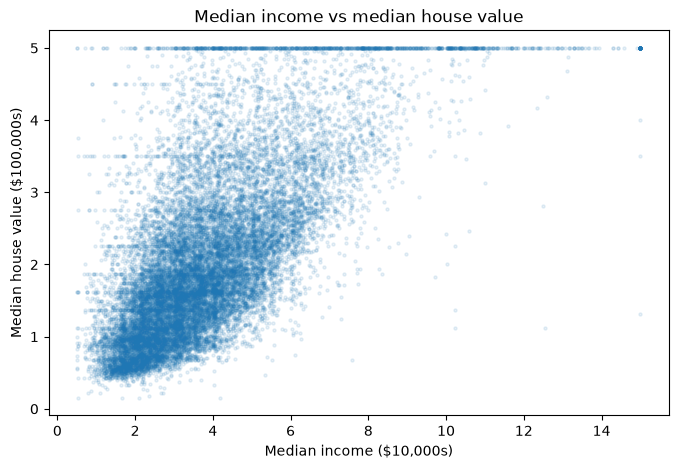

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

# One dot per block group; alpha makes overlapping dots show as darker areas
ax.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1, s=5)

ax.set_title("Median income vs median house value")
ax.set_xlabel("Median income ($10,000s)")
ax.set_ylabel("Median house value ($100,000s)")
plt.show()

## 8. Where are the expensive areas?

Plotting `Longitude` on the x-axis and `Latitude` on the y-axis places each block group where it sits on the ground, so the dots draw a map of California.

Three additions colour the map by price:

- `c=df["MedHouseVal"]` sets each dot's colour from its house value.
- `cmap="viridis"` chooses the **colormap**, the scale that turns numbers into colours. Dark purple is low and yellow is high.
- `fig.colorbar` adds the **colorbar**, the strip on the right that shows which colour means which value.

What the map shows:

- **Two yellow clusters on the coast**: the San Francisco Bay Area (around longitude -122, latitude 37.5) and Los Angeles (around -118, 34).
- **Inland areas are mostly dark purple**, the cheap end of the scale.

**Finding:** location also matters for price. `Latitude` and `Longitude` scored close to 0 in section 6 because correlation only measures straight-line patterns. The real pattern is "near the coast and near a big city", which no straight line captures.

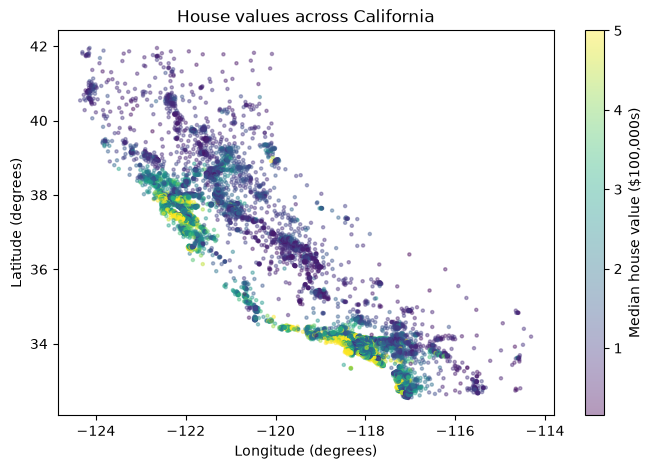

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))

# c= colours each dot by its house value; cmap picks the colour scale
points = ax.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    alpha=0.4,
    s=5,
)

# The colorbar shows which colour means which house value
fig.colorbar(points, ax=ax, label="Median house value ($100,000s)")

ax.set_title("House values across California")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
plt.show()

## 9. Do more rooms mean a higher price?

`AveRooms` is the average number of rooms per household in a block group. This is the same kind of scatter plot as section 7, with `AveRooms` on the x-axis.

A few block groups have extreme values: the `max` in section 2 is about 142 rooms, while three quarters of the rows are below about 6. Values this far from the rest are called **outliers**, and they stretch the axis until every other dot is squashed against the left edge. `ax.set_xlim(0, 15)` zooms the view in on the typical range. It only changes what is shown: 109 block groups sit beyond 15 and are still in `df`.

What the plot shows:

- **A slight upward drift.** More rooms go with somewhat higher prices.
- **A round cloud, not a rising band.** At 5 rooms, prices run from under 1 up to the cap at 5.

**Finding:** rooms are a weaker feature than income and location. The correlation is 0.15, against 0.69 for income.

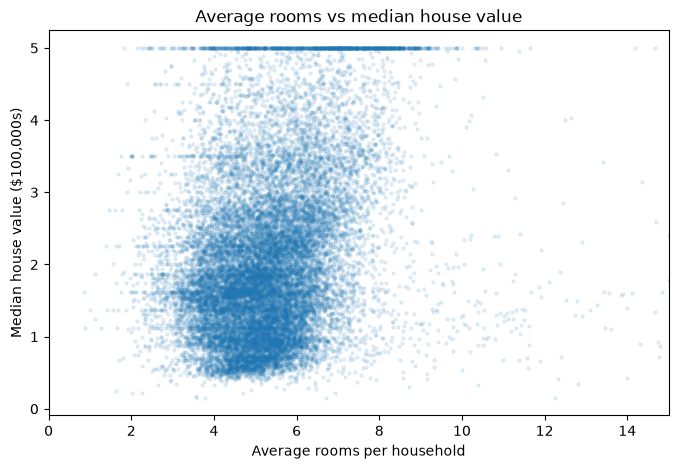

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))

# One dot per block group; alpha makes overlapping dots show as darker areas
ax.scatter(df["AveRooms"], df["MedHouseVal"], alpha=0.1, s=5)

# A few block groups average over 100 rooms; zoom in on the typical range
ax.set_xlim(0, 15)

ax.set_title("Average rooms vs median house value")
ax.set_xlabel("Average rooms per household")
ax.set_ylabel("Median house value ($100,000s)")
plt.show()

## 10. Summary

**About the data**

- 20,640 block groups, 8 features and one target, with no missing values.
- House values are right-skewed and capped at 5.0 ($500,000), so the most expensive areas are all recorded at the cap.
- `AveRooms` has extreme outliers.

**What is linked to price**

| Question | Finding |
|---|---|
| Which column is most linked to price? | `MedInc`, with a correlation of 0.69 |
| Do richer areas have pricier houses? | Yes, in a wide rising band |
| Where are the expensive areas? | On the coast, around San Francisco and Los Angeles |
| Do more rooms mean a higher price? | Only slightly, with a correlation of 0.15 |

**What this means for modelling**

- Income should be the most useful single feature.
- Location matters, but not in a straight line, so a model that only fits straight lines will struggle to use `Latitude` and `Longitude`.
- A model cannot learn prices above the cap, so it will underestimate the most expensive areas.